In [ ]:
# Feature Engineering

In [ ]:
'''
Feature engineering is the process of using domain knowledge and statistical methods to transform raw data into meaningful input features that help machine learning models learn and make more accurate predictions.
Feature engineering is the process of using domain knowledge to extract features from raw data.

Datasets --> Data Retrival --> Data Preprocessing & Wrangling --> Feature Extraction & Engineering --> Feature Scaling & Selection --> Model Training & Evaluation --> Model Deployment & Monitoring

Feature Engineering types-
  1. Feature Transformation (Modifying and changing/transforming a column to a new form so that it can perform better)
     - Missing value imputation (Removing missing values or filling the missing values using some proper technique)
     - Handling Categorical Features (Computer only understands binary/numerical. So converting data or transforming data into a different form(numerical).  The process of converting non-numerical or categorical data (such as text, labels, or strings) into a numerical format so that machine learning algorithms can process them.)
     - Outlier Detection (Exceptional data that can damage our model training and not related to most of the data point. It's necessary to remove those data)
     - Feature Scaling (If features has too big difference in range then we have to scale them and transform them for a certain given range)
  2. Feature Construction (There are some features which not included in the dataset but we need to derive it manually from other features so that our model improves)
  3. Featuere Selection (Selecting only necessary features and excluding unnecessary features)
  4. Feature Extraction (Extracting completely new features from give features programmatically)

'''

In [ ]:
# Feature Scaling - Standardization (Most probably the last part of Feature Engineering)

'''
Feature scaling is a technique to standardize the independent features present in the data in a fixed range.

Types of feature scaling-
  1. Standardization/Z-score Normalization
  2. Normalization(Min-Max Scaling, Robust Scaling)

1. Standardization
  - Formula: x_bar = (x - mean(x)) / std(x)
  - After standardize a column the mean of the new column is always zero and Standard Deviation(SD) is always 1.
  - The shape of the distribution remains same after and before the standardization of a column.
  - If any column has outlier then standardization has no impact on outlier. It remains as it is so we have to handle it manually.
  - When we are working with these following algorithm we can use standardization - K-Means, KNN, PCA, ANN, Gradient Descent
'''

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/content/Social_Network_Ads.csv')
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [4]:
df = df.iloc[:,2:]

In [5]:
df.sample(5)

,Age,EstimatedSalary,Purchased
63,32,120000,1
178,24,23000,0
196,30,79000,0
91,30,116000,0
369,54,26000,1


Before Feature Scaling

In [7]:
# Train Test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1),
                                                    df['Purchased'],
                                                    test_size =0.3,
                                                    random_state=0)

X_train.shape, X_test.shape

((280, 2), (120, 2))

In [8]:
# Use StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# fit the scaler to the train set, it will learn the parameter
scaler.fit(X_train)

# transform train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
scaler.mean_

array([3.78642857e+01, 6.98071429e+04])

In [12]:
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_train_scaled.head()

,Age,EstimatedSalary
0,-1.163172,-1.584970
1,2.170181,0.930987
2,0.013305,1.220177
3,0.209385,1.075582
4,0.405465,-0.486047


In [14]:
X_train_scaled_desc = np.round(X_train_scaled.describe(),1)
X_train_scaled_desc

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


Effect of Scaling

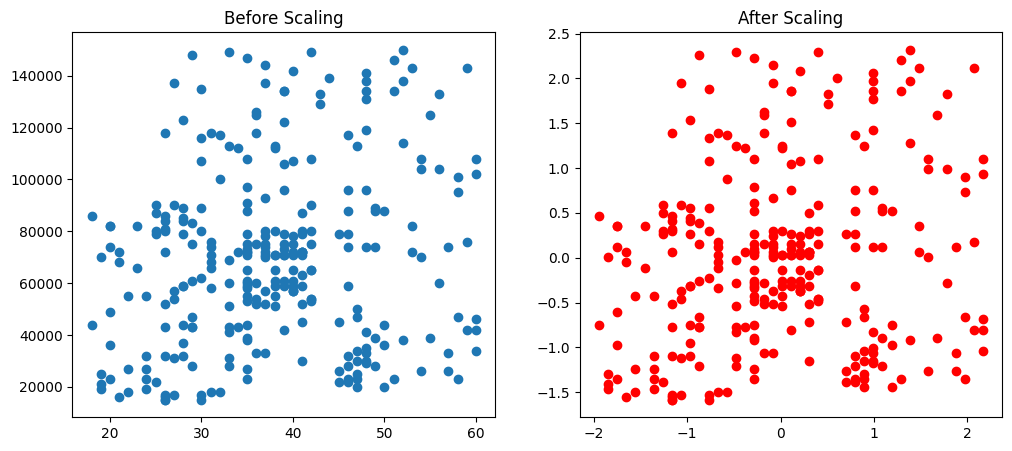

In [17]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title('Before Scaling')
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax2.set_title('After Scaling')
plt.show()

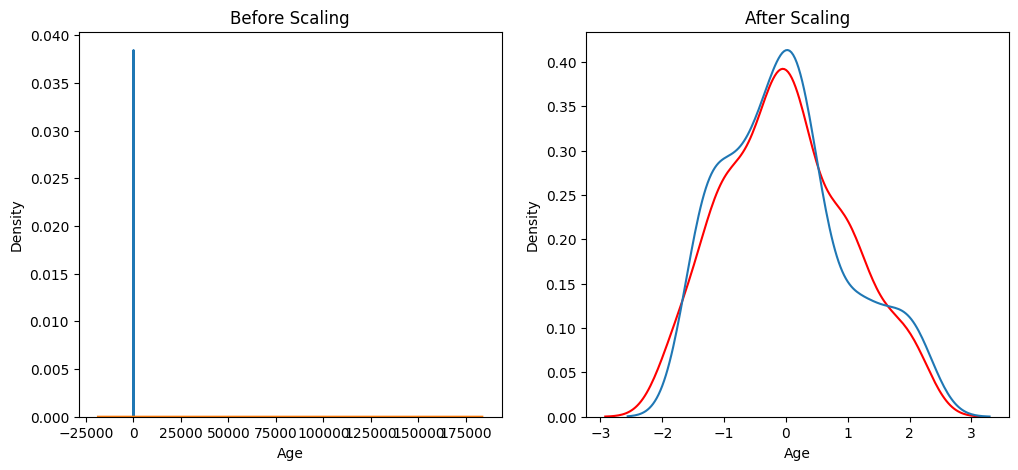

In [22]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))

# before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1)
sns.kdeplot(X_train['EstimatedSalary'], ax=ax1)


# after scaling
ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Age'], ax=ax2, color='red')
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax=ax2)

plt.show()